# RUL-cap and feature-set experiment (Phase 1)

**Owner:** Ashrith

Two questions:

1. **Cap question:** how does *training* on `min(RUL, 125)` change the overall, early and late error, graded against **true** RUL? Under `docs/EVALUATION_PROTOCOL.md` Section 1, capped training is adopted only if the overall RMSE is no worse than without the cap **and** the late band improves.
2. **Rolling-features question:** do Random Forest and gradient boosting do better with all 57 features or with `cycle` + 14 raw sensors (15 features)?

Early = true RUL > 125, late = true RUL <= 125. Groups are formed from true RUL after predicting; the model never sees them.

*Validation only. The test set is not loaded in this notebook.*

## Setup and data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from rul_prediction.cap_experiment import run_cap_grid
from rul_prediction.data import load_cmapss_file
from rul_prediction.features import add_rolling_features, model_feature_columns, select_informative_sensors
from rul_prediction.metrics import RUL_BAND_THRESHOLD
from rul_prediction.models.tree_models import make_gradient_boosting, make_random_forest
from rul_prediction.splits import DEFAULT_SEED, sample_cutoff_rows, split_by_engine, split_engine_ids
from rul_prediction.targets import add_train_rul

RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

train = add_train_rul(load_cmapss_file(PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"))
train_ids, val_ids = split_engine_ids(train["engine_id"])
train_raw, val_raw = split_by_engine(train, val_ids)
sensors = select_informative_sensors(train_raw)
train_df = add_rolling_features(train_raw, sensors)
val_df = add_rolling_features(val_raw, sensors)
val_points = sample_cutoff_rows(val_df)

pinned = pd.read_csv(PROJECT_ROOT / "docs" / "fd001_validation_cutoffs.csv")
pd.testing.assert_frame_equal(val_points[["engine_id", "cycle", "rul"]], pinned)
print(len(train_df), "training rows,", len(val_points), "validation points,", len(sensors), "sensors")

16390 training rows, 100 validation points, 14 sensors


## Experiment settings (fixed; not retuned here)

In [2]:
FEATURE_SETS = {
    "v2 (57, with rolling)": model_feature_columns(sensors),
    "cycle + 14 raw (15, no rolling)": ["cycle"] + sensors,
}
# Settings chosen on validation in 03_linear_baseline and 03_tree_models. Not retuned here.
MODEL_BUILDERS = {
    "Elastic Net": lambda: make_pipeline(StandardScaler(), ElasticNet(alpha=1, l1_ratio=0.5, max_iter=50_000)),
    "Random Forest": lambda: make_random_forest(n_estimators=300, min_samples_leaf=20, max_features=0.33),
    "Gradient boosting": lambda: make_gradient_boosting(learning_rate=0.05, max_iter=200, max_depth=3),
}
CAPS = {"no cap": None, "cap 125": 125}

## Run the grid (2 caps x 2 feature sets x 3 models)

In [3]:
results, predictions = run_cap_grid(train_df, val_points, FEATURE_SETS, MODEL_BUILDERS, CAPS)
results.round(2)

,cap,features,n_features,model,n,mae,rmse,early_n,early_mae,early_rmse,late_n,late_mae,late_rmse,rmse_vs_capped_key
0,no cap,"v2 (57, with rolling)",57,Elastic Net,100,31.66,41.77,22,46.31,66.02,78,27.52,31.74,NaN
1,no cap,"v2 (57, with rolling)",57,Random Forest,100,25.03,40.17,22,49.33,69.59,78,18.17,26.50,NaN
2,no cap,"v2 (57, with rolling)",57,Gradient boosting,100,26.12,40.17,22,50.92,69.54,78,19.13,26.54,NaN
3,no cap,"cycle + 14 raw (15, no rolling)",15,Elastic Net,100,31.42,41.74,22,45.67,65.15,78,27.40,32.19,NaN
4,no cap,"cycle + 14 raw (15, no rolling)",15,Random Forest,100,24.40,37.13,22,48.70,66.02,78,17.54,23.20,NaN
5,no cap,"cycle + 14 raw (15, no rolling)",15,Gradient boosting,100,24.02,36.44,22,49.36,64.43,78,16.88,23.05,NaN
6,cap 125,"v2 (57, with rolling)",57,Elastic Net,100,28.00,44.20,22,69.10,86.89,78,16.40,19.36,20.37
7,cap 125,"v2 (57, with rolling)",57,Random Forest,100,24.35,42.48,22,65.40,85.24,78,12.77,16.27,17.32
8,cap 125,"v2 (57, with rolling)",57,Gradient boosting,100,24.03,41.83,22,65.01,83.99,78,12.47,15.93,17.11
9,cap 125,"cycle + 14 raw (15, no rolling)",15,Elastic Net,100,28.32,44.23,22,69.16,86.67,78,16.80,19.73,20.66


## Sanity checks: no-cap rows must reproduce the published numbers

In [4]:
expected_no_cap_rmse = {
    ("v2 (57, with rolling)", "Elastic Net"): 41.77,
    ("v2 (57, with rolling)", "Random Forest"): 40.17,
    ("v2 (57, with rolling)", "Gradient boosting"): 40.17,
    ("cycle + 14 raw (15, no rolling)", "Elastic Net"): 41.74,
    ("cycle + 14 raw (15, no rolling)", "Random Forest"): 37.13,
    ("cycle + 14 raw (15, no rolling)", "Gradient boosting"): 36.44,
}
no_cap = results[results["cap"] == "no cap"].set_index(["features", "model"])
for key, value in expected_no_cap_rmse.items():
    assert abs(no_cap.loc[key, "rmse"] - value) < 0.006, (key, no_cap.loc[key, "rmse"], value)
assert (results["n"] == 100).all()
assert (results["early_n"] == 22).all() and (results["late_n"] == 78).all()
print("sanity checks passed")

sanity checks passed


## Question 1: what does capped training change?

`change` < 0 means capped training lowered that error. `passes_rule` applies the protocol rule to each run: overall RMSE no worse **and** late RMSE better.

In [5]:
cap_table = results.pivot_table(
    index=["features", "model"], columns="cap", values=["rmse", "early_rmse", "late_rmse"]
)
for metric in ["rmse", "early_rmse", "late_rmse"]:
    cap_table[(metric, "change")] = cap_table[(metric, "cap 125")] - cap_table[(metric, "no cap")]
cap_table["passes_rule"] = (cap_table[("rmse", "change")] <= 0) & (cap_table[("late_rmse", "change")] < 0)
cap_table.round(2)

early_rmse        late_rmse  \
cap                                                  cap 125 no cap   cap 125   
features                        model                                           
cycle + 14 raw (15, no rolling) Elastic Net            86.67  65.15     19.73   
                                Gradient boosting      84.11  64.43     15.38   
                                Random Forest          84.14  66.02     15.19   
v2 (57, with rolling)           Elastic Net            86.89  66.02     19.36   
                                Gradient boosting      83.99  69.54     15.93   
                                Random Forest          85.24  69.59     16.27   

                                                            rmse         \
cap                                               no cap cap 125 no cap   
features                        model                                     
cycle + 14 raw (15, no rolling) Elastic Net        32.19   44.23  41.74   
                                Gradient boosting  23.05   41.72  36.44   
                                Random Forest      23.20   41.68  37.13   
v2 (57, with rolling)           Elastic Net        31.74   44.20  41.77   
                                Gradient boosting  26.54   41.83  40.17   
                                Random Forest      26.50   42.48  40.17   

                                                         early_rmse late_rmse  \
cap                                               change     change    change   
features                        model                                           
cycle + 14 raw (15, no rolling) Elastic Net         2.49      21.53    -12.46   
                                Gradient boosting   5.29      19.68     -7.67   
                                Random Forest       4.55      18.12     -8.01   
v2 (57, with rolling)           Elastic Net         2.43      20.88    -12.38   
                                Gradient boosting   1.67      14.45    -10.61   
                                Random Forest       2.32      15.65    -10.23   

                                                  passes_rule  
cap                                                            
features                        model                          
cycle + 14 raw (15, no rolling) Elastic Net             False  
                                Gradient boosting       False  
                                Random Forest           False  
v2 (57, with rolling)           Elastic Net             False  
                                Gradient boosting       False  
                                Random Forest           False

## Question 2: do the rolling features help the trees?

A positive "rolling minus no rolling" means the rolling features made that error **worse**.

In [6]:
no_cap = results[results["cap"] == "no cap"]
feature_table = no_cap.pivot_table(index="model", columns="features", values=["rmse", "late_rmse"])
for metric in ["rmse", "late_rmse"]:
    feature_table[(metric, "rolling minus no rolling")] = (
        feature_table[(metric, "v2 (57, with rolling)")]
        - feature_table[(metric, "cycle + 14 raw (15, no rolling)")]
    )
feature_table.round(2)

late_rmse                        \
features          cycle + 14 raw (15, no rolling) v2 (57, with rolling)   
model                                                                     
Elastic Net                                 32.19                 31.74   
Gradient boosting                           23.05                 26.54   
Random Forest                               23.20                 26.50   

                                             rmse                        \
features          cycle + 14 raw (15, no rolling) v2 (57, with rolling)   
model                                                                     
Elastic Net                                 41.74                 41.77   
Gradient boosting                           36.44                 40.17   
Random Forest                               37.13                 40.17   

                                                          late_rmse  
features          rolling minus no rolling rolling minus no rolling  
model                                                                
Elastic Net                           0.03                    -0.45  
Gradient boosting                     3.73                     3.49  
Random Forest                         3.04                     3.31

## Capped-answer score (explanation only)

Capped-answer score: graded against min(RUL, 125) instead of true RUL. Shown only to explain why capped results look so low. Not comparable with any other number in this notebook, nor with published test-set results.

In [7]:
results[results["cap"] == "cap 125"][["features", "model", "rmse_vs_capped_key"]].round(2)

,features,model,rmse_vs_capped_key
6,"v2 (57, with rolling)",Elastic Net,20.37
7,"v2 (57, with rolling)",Random Forest,17.32
8,"v2 (57, with rolling)",Gradient boosting,17.11
9,"cycle + 14 raw (15, no rolling)",Elastic Net,20.66
10,"cycle + 14 raw (15, no rolling)",Random Forest,16.78
11,"cycle + 14 raw (15, no rolling)",Gradient boosting,17.01


## Figure: best no-cap run vs best cap-125 run (lowest overall RMSE)

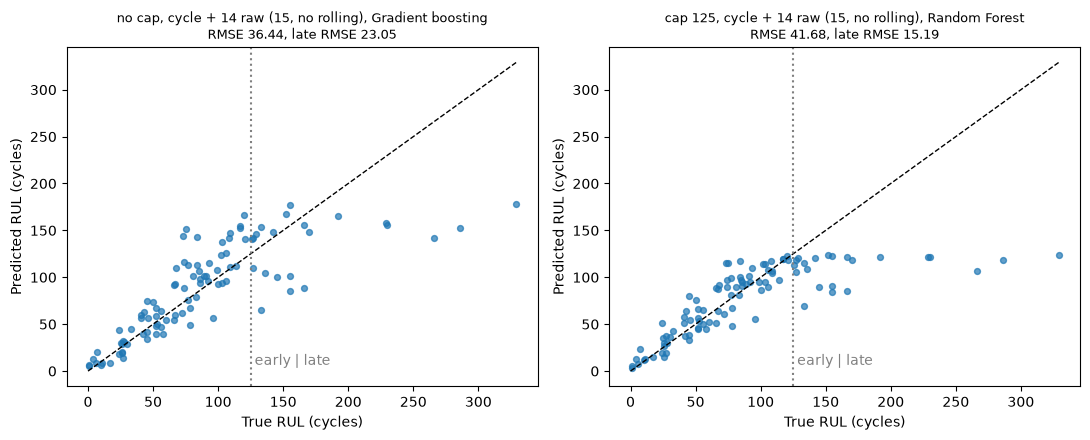

In [8]:
best_runs = [
    results[results["cap"] == cap_name].sort_values("rmse").iloc[0]
    for cap_name in ["no cap", "cap 125"]
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, run in zip(axes, best_runs):
    pred = predictions[(run["cap"], run["features"], run["model"])]
    ax.scatter(val_points["rul"], pred, s=18, alpha=0.7)
    top = max(val_points["rul"].max(), pred.max())
    ax.plot([0, top], [0, top], "k--", linewidth=1)
    ax.axvline(RUL_BAND_THRESHOLD, color="gray", linestyle=":")
    ax.text(RUL_BAND_THRESHOLD, top * 0.02, " early | late", color="gray")
    ax.set_title(
        f"{run['cap']}, {run['features']}, {run['model']}\n"
        f"RMSE {run['rmse']:.2f}, late RMSE {run['late_rmse']:.2f}",
        fontsize=9,
    )
    ax.set_xlabel("True RUL (cycles)")
    ax.set_ylabel("Predicted RUL (cycles)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rul_cap_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

## Save results and experiment log (written by code)

In [9]:
results.to_csv(RESULTS_DIR / "rul_cap_experiment.csv", index=False)

log = f"""# Experiment log — RUL cap and feature set

- **Owner:** Ashrith
- **Notebook:** notebooks/03_rul_cap_experiment.ipynb
- **Question:** (1) How does training on min(RUL, 125) change overall, early and late error graded on true RUL, and does it pass the protocol rule? (2) Do trees do better with all 57 features or cycle + 14 raw sensors (15)?
- **Dataset/subset:** FD001
- **Split protocol / engine IDs:** engine ID 80/20, seed {DEFAULT_SEED}, 100 val cut-offs (docs/fd001_validation_cutoffs.csv); validation engines {sorted(val_ids)}
- **Target settings (including any RUL cap):** trained on true RUL or min(RUL, 125); always graded on true RUL
- **Features or window length:** {", ".join(f"{name} ({len(cols)})" for name, cols in FEATURE_SETS.items())}
- **Models and hyperparameters:** Elastic Net (StandardScaler, alpha=1, l1_ratio=0.5, max_iter=50000); Random Forest (n_estimators=300, min_samples_leaf=20, max_features=0.33); Gradient boosting (learning_rate=0.05, max_iter=200, max_depth=3); not retuned
- **Random seed:** {DEFAULT_SEED}
- **Other settings:** scikit-learn {sklearn.__version__}, pandas {pd.__version__}, numpy {np.__version__}
- **Band threshold:** early = true RUL > {RUL_BAND_THRESHOLD}, late = true RUL <= {RUL_BAND_THRESHOLD}; band counts: early {int(results["early_n"].iloc[0])}, late {int(results["late_n"].iloc[0])}
- **Validation MAE / RMSE:** see reports/results/rul_cap_experiment.csv (one row per run)
- **Test MAE / RMSE:** not run (validation-only experiment)
- **Plots/results file:** reports/figures/rul_cap_predicted_vs_actual.png, reports/results/rul_cap_experiment.csv
- **Interpretation:** see the Findings section of the notebook
"""
(RESULTS_DIR / "rul_cap_experiment_log.md").write_text(log)
print(log)

# Experiment log — RUL cap and feature set

- **Owner:** Ashrith
- **Notebook:** notebooks/03_rul_cap_experiment.ipynb
- **Question:** (1) How does training on min(RUL, 125) change overall, early and late error graded on true RUL, and does it pass the protocol rule? (2) Do trees do better with all 57 features or cycle + 14 raw sensors (15)?
- **Dataset/subset:** FD001
- **Split protocol / engine IDs:** engine ID 80/20, seed 42, 100 val cut-offs (docs/fd001_validation_cutoffs.csv); validation engines [8, 9, 13, 18, 37, 46, 48, 50, 55, 62, 64, 69, 72, 74, 76, 84, 85, 87, 90, 95]
- **Target settings (including any RUL cap):** trained on true RUL or min(RUL, 125); always graded on true RUL
- **Features or window length:** v2 (57, with rolling) (57), cycle + 14 raw (15, no rolling) (15)
- **Models and hyperparameters:** Elastic Net (StandardScaler, alpha=1, l1_ratio=0.5, max_iter=50000); Random Forest (n_estimators=300, min_samples_leaf=20, max_features=0.33); Gradient boosting (learning_ra

## Findings

**Caveat.** Only 20 validation engines (100 points; 22 early from 14 engines, 78 late) were used. Differences of 1–2 cycles may be noise. Numbers are compared only within the same column of the tables above.

**Question 1 — does capped training pass the protocol rule?**

- Overall RMSE got **worse** for all 6 runs when training on `min(RUL, 125)` (for example Random Forest on 15 features: 37.13 → 41.68; gradient boosting on 15 features: 36.44 → 41.72).
- Late RMSE improved for all 6 runs (for example gradient boosting on 57 features: 26.54 → 15.93).
- Early RMSE moved in the **opposite** direction: it got worse in every run (for example Random Forest on 57 features: 69.59 → 85.24). The cap makes the model predict lower values, which helps near failure and hurts healthy engines.
- `passes_rule` is **False for all 6 runs**: the protocol requires overall RMSE no worse **and** late better, and only the late condition is met.
- The capped-answer score (`rmse_vs_capped_key`, 16.78–20.66) looks much lower because it is graded against a different, capped answer key. It is not comparable with any other number.

**Question 2 — do rolling features help the trees (no cap)?**

- Random Forest: overall RMSE 40.17 (57 features) vs 37.13 (15 features); late RMSE 26.50 vs 23.20.
- Gradient boosting: overall 40.17 vs 36.44; late 26.54 vs 23.05.
- In both tree models the 57-feature set is worse by about 3 cycles overall and in the late band, which is larger than the 1–2 cycle noise range, though still from only 20 engines.
- Elastic Net (not a tree model) is essentially tied overall (41.77 vs 41.74).

**Recommendations (the team decides):**

1. **Cap:** do not adopt. It fails the protocol rule on every run. Its late-band gain comes with a worse overall RMSE and a clearly worse early band.
2. **Rolling features for trees:** the 15-feature set looks better for both tree models, but the evidence is from a single split of 20 engines, so treat this as "needs team confirmation" rather than a settled result.
